## Setup Libraries

In [1]:
!pip install -q pytabkit

In [2]:
try:
    from colorama import Fore, Style
except:
    !pip install -q colorama
    from colorama import Fore, Style

%matplotlib inline
%config InlineBackend.figure_format = 'svg'

In [3]:
try:
    import xgboost
except:
    !pip install -q xgboost
    import xgboost

try:
    import lightgbm
except:
    !pip install -q lightgbm
    import lightgbm

try:
    import catboost
except:
    !pip install -q catboost
    import catboost

In [4]:
import random
import warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from importlib.metadata import version
from time import time

from sklearn.calibration import CalibrationDisplay
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import KBinsDiscretizer, TargetEncoder
from sklearn.metrics import roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay

import torch
import pytabkit
from pytabkit import XGB_TD_Classifier, LGBM_TD_Classifier, CatBoost_TD_Classifier

warnings.filterwarnings('ignore')
print("PyTorch  version:", torch.__version__)
print("PyTabKit version:", version("pytabkit"))

## -- Global Settings --
# sklearn.set_config(transform_output='pandas')

# pd.options.mode.copy_on_write = True
pd.set_option('display.max_columns', 100)
# sns.set_style("whitegrid")
# plt.style.use('ggplot')

def seed_everything(seed: int):
    print(f"🌱 Seeding everything with {seed}")
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

seed_everything(42)

PyTorch  version: 2.11.0+cpu
PyTabKit version: 1.8.0
🌱 Seeding everything with 42


In [5]:
TEAL, GOLD, CORAL, BLUE, DARK, CRIM, MUTED, INK, PAPER = '#168c91','#e8b44f','#dc705a',\
                                                         'dodgerblue','#0B4F7A','crimson',\
                                                         '#627D98','#102A43','#faf9f5'
plt.rcParams.update({
    'figure.facecolor': PAPER,
    'axes.facecolor': PAPER,
    'savefig.facecolor': PAPER,
    'font.family': 'DejaVu Sans',
    'font.size': 9,
    'axes.titlesize': 11,
    'axes.titleweight': 'semibold',
    'axes.labelcolor': INK,
    'text.color': INK,
    'xtick.color': DARK,
    'ytick.color': DARK,
    'axes.edgecolor': MUTED,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.color': MUTED,
    'patch.edgecolor': DARK,
    # 'patch.force_edgecolor': True,
    # 'patch.linewidth': 1.5,
    # 'figure.dpi':110,
    # 'savefig.dpi':160,
})

## Load Data

In [6]:
## -- ⚠️ IMPORTANT: SELECT PLATFORM ⚠️ --
PLATFORM = "kaggle" # -> 'colab' 'kaggle'

if PLATFORM == "kaggle":
    PATH   = "/kaggle/input/competitions/playground-series-s6e11/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    ORIG_PATH = "/kaggle/input/datasets/uditjain13/credit-card-fraud-detection-2026/"
    orig = pd.read_csv(ORIG_PATH+"credit_card_fraud_2026.csv")
elif PLATFORM == "colab":
    from google.colab import drive
    drive.mount("/content/drive")
    PATH   = "/content/drive/MyDrive/-- shared_notebooks --/Ps6e11 | Credit Card Fraud/_fraud_data/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    orig   = pd.read_csv(PATH+"credit_card_fraud_2026.csv")

## =================================================================================

for (name, df) in {"Train": train, "Test": test, 'Orig': orig}.items(): #
    print(f"{name} shape: {df.shape}")

print(f"\nFrame type: {type(train)}")

train_len = len(train)
test_len  = len(test)

n_unique = train.nunique().sort_values()
n_unique

Train shape: (699960, 26)
Test shape: (299984, 25)
Orig shape: (20000, 26)

Frame type: <class 'pandas.core.frame.DataFrame'>


is_new_merchant                      2
is_fraud                             2
is_ai_generated_scam_attempt         2
billing_shipping_mismatch            2
ip_country_mismatch                  2
used_vpn                             2
is_foreign_transaction               2
cvv_retry_count                      4
auth_method                          5
prior_disputes                       5
card_type                            5
channel                              5
day_of_week                          7
device_type                          8
txn_count_last_24h                  12
merchant_category                   12
time_of_day_hour                    24
card_age_months                     49
customer_age                        64
velocity_score                     666
merchant_risk_score                950
hours_since_last_txn              3633
distance_from_home_km             4365
amount_usd                       13387
account_balance_usd              43317
id                       

## Preprocess Features

In [7]:
ID = 'id'
TARGET = 'is_fraud'

X = train.drop([ID, TARGET], axis=1); train_id = train[ID]
y = train[TARGET]
X_test = test.drop([ID], axis=1); test_id = test[ID]

del train, test
print('-'*40)
print("X      init shape:", X.shape)
print("X_test init shape:", X_test.shape, "\n")

cat_cols = X.select_dtypes(include=['object', 'bool']).columns.tolist()
num_cols = X.select_dtypes(exclude=['object', 'bool']).columns.tolist()
base_cols = cat_cols + num_cols
print("init len(cat_cols):", len(cat_cols))
print("init len(num_cols):", len(num_cols), "\n")

category_map = {}
important_combos = [
    ('merchant_category', 'card_type', 'txn_count_last_24h'),
    ('merchant_category', 'customer_age'),
]
def feature_engineering(df, fit=False):
    # Digit extraction
    for col in ['amount_usd', 'hours_since_last_txn',
                'velocity_score', 'distance_from_home_km']:
        decimal_name = f"_{col}_decimal"
        df[decimal_name] = (df[col] % 1).round(2).astype('float32')

    # Categorize numericals
    for col in num_cols + ['_amount_usd_decimal', '_hours_since_last_txn_decimal',
                           '_velocity_score_decimal', '_distance_from_home_km_decimal']:
        cat_name = f"{col}_cat_" if col in num_cols else f"{col[1:]}_cat_"
        values = np.floor(df[col]) if col in num_cols else df[col]
        if fit:
            codes, uniques = values.factorize()
            category_map[col] = uniques
        else:
            uniques = category_map[col]
            code_map = {cat: i for i, cat in enumerate(uniques)}
            codes = values.map(code_map).fillna(-1).astype('int32')
        df[cat_name] = codes
        df[cat_name] = df[cat_name].astype('category')

    # Discretize numericals
    bin_config = {'merchant_risk_score': [7], 'hours_since_last_txn': [500, 1000]}
    for col, bins_list in bin_config.items():
        for n_bins in bins_list:
            for strategy in ['quantile']:
                bin_name = f"{col}_{n_bins}_{strategy}_bin_"
                if fit:
                    kb = KBinsDiscretizer(
                        n_bins=n_bins,
                        encode='ordinal',
                        strategy=strategy,
                        subsample=None
                    )
                    binned = kb.fit_transform(df[[col]]).ravel().astype('int32')
                    category_map[bin_name] = kb
                else:
                    kb = category_map[bin_name]
                    binned = kb.transform(df[[col]]).ravel().astype('int32')
                df[bin_name] = binned
                df[bin_name] = df[bin_name].astype('category')

    # Create interaction categories
    combo_names = []
    for cols in important_combos:
        combo_name = '_'.join(cols) + '_'
        combo_names.append(combo_name)
        combo_series = df[cols[0]].astype(str)
        for col in cols[1:]:
            combo_series = combo_series + '_' + df[col].astype(str)
        if fit:
            codes, uniques = pd.factorize(combo_series, sort=False)
            category_map[combo_name] = uniques
        else:
            uniques = category_map[combo_name]
            code_map = {cat: i for i, cat in enumerate(uniques)}
            codes = combo_series.map(code_map).fillna(-1).astype('int32')
        df[combo_name] = codes
        df[combo_name] = df[combo_name].astype('category')

    new_cat_cols = [col for col in df.columns if col.endswith('_')]
    new_num_cols = [col for col in df.columns if col.startswith('_')]
    return df, new_cat_cols, new_num_cols, combo_names

X, new_cat_cols, new_num_cols, combo_names = feature_engineering(X, fit=True)
X_test, _, _, _ = feature_engineering(X_test, fit=False)
cat_cols += new_cat_cols; num_cols += new_num_cols
print("len(new_cat_cols):", len(new_cat_cols))
print("len(new_num_cols):", len(new_num_cols), "\n")

print("prep len(cat_cols):", len(cat_cols))
print("prep len(num_cols):", len(num_cols), "\n")
print("X      prep shape:", X.shape)
print("X_test prep shape:", X_test.shape)
print('-'*40)

----------------------------------------
X      init shape: (699960, 24)
X_test init shape: (299984, 24) 

init len(cat_cols): 11
init len(num_cols): 13 

len(new_cat_cols): 22
len(new_num_cols): 4 

prep len(cat_cols): 33
prep len(num_cols): 17 

X      prep shape: (699960, 50)
X_test prep shape: (299984, 50)
----------------------------------------


In [8]:
X.head()

,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,_amount_usd_decimal,_hours_since_last_txn_decimal,_velocity_score_decimal,_distance_from_home_km_decimal,amount_usd_cat_,hours_since_last_txn_cat_,txn_count_last_24h_cat_,distance_from_home_km_cat_,card_age_months_cat_,customer_age_cat_,account_balance_usd_cat_,cvv_retry_count_cat_,velocity_score_cat_,time_of_day_hour_cat_,day_of_week_cat_,merchant_risk_score_cat_,prior_disputes_cat_,amount_usd_decimal_cat_,hours_since_last_txn_decimal_cat_,velocity_score_decimal_cat_,distance_from_home_km_decimal_cat_,merchant_risk_score_7_quantile_bin_,hours_since_last_txn_500_quantile_bin_,hours_since_last_txn_1000_quantile_bin_,merchant_category_card_type_txn_count_last_24h_,merchant_category_customer_age_
0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,Groceries,Mastercard,OTP,POS,iPhone,False,False,False,False,False,False,0.16,0.77,0.5,0.78,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,371,553,0,0
1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,Online Retail,Visa,PIN,In-App,Android Phone,False,False,False,False,False,False,0.83,0.54,0.4,0.06,1,1,1,1,1,1,1,0,1,1,1,0,1,1,1,1,1,2,80,104,1,1
2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,Utilities,Visa,OTP,Online,Tablet,False,False,True,False,False,False,0.36,0.20,0.8,0.17,2,1,2,2,2,2,2,0,2,2,2,1,0,2,2,2,2,1,59,79,2,2
3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,3,41.9,0,Groceries,Mastercard,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.44,0.13,0.7,0.67,3,2,2,2,0,3,3,0,3,3,0,2,0,3,3,3,3,5,251,338,3,3
4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,4,48.0,0,Electronics,Visa,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.85,0.80,0.8,0.69,4,3,2,3,3,4,4,0,4,4,3,3,0,4,4,2,4,5,42,54,4,4


## Config

In [32]:
xgb_m = XGB_TD_Classifier(**{
    'n_estimators': 20_000, # d=1000
    'max_depth': 2, # d=6
    'lr': 0.015, # d=0.08
    'subsample': 0.95, # d=0.65
    'colsample_bytree': 0.3, # d=0.9
    'colsample_bylevel': 0.75, # d=0.9
    # 'min_child_weight': 1, # d=5e-06
    # 'alpha': 3.0,
    # 'reg_lambda': 0.01, # d=0.0
    # 'max_bin': 512, # d=256
    # 'max_cat_to_onehot': 10,
    # 'verbosity': 0,
    'val_metric_name': "1-auc_ovr",
    'random_state': 42,
})

lgb_m = LGBM_TD_Classifier(**{
    'n_estimators': 20_000, # d=1000
    'num_leaves': 3, # d=50
    'lr': 0.015, # d=0.04
    # -------------------------------
    'subsample': 0.95, # d=0.75
    'colsample_bytree': 0.3, # d=1.0
    # 'bagging_freq': 2, # d=1
    # -------------------------------
    # 'min_data_in_leaf': 80, # d=40
    # 'max_bin': 512, # d=255
    # -------------------------------
    'lambda_l1': 0.001,
    'lambda_l2': 0.001, # ⚡️
    'val_metric_name': "1-auc_ovr",
    'random_state': 42,
})

cat_bay = CatBoost_TD_Classifier(**{
    'bootstrap_type': "Bayesian",
    # -------------------------------
    'n_estimators': 10_000, # d=1000 ⚡️
    'max_depth': 4, # d=7
    # 'lr': 0.07, # d=0.08 ⚡️
    # 'max_bin': 512, # d=254
    # -------------------------------
    # 'l2_leaf_reg': 0.001, # d=1e-05 ⚡️
    # 'leaf_estimation_iterations': 2, # d=1
    'random_strength': 1.0, # d=0.8
    # -------------------------------
    # 'one_hot_max_size': 10, # d=15
    # 'verbosity': 0,
    'random_state': 42,
})

cat_ben = CatBoost_TD_Classifier(**{
    'bootstrap_type': "Bernoulli",
    # 'n_estimators': 10_000, # ⚡️
    # 'subsample': 0.8, # d=0.9
    # 'max_depth': 2, # ⚡️
    # 'lr': 0.04, # ⚡️
    # 'l2_leaf_reg': 0.1, # ⚡️
    # 'random_strength': 0.6,
    # 'one_hot_max_size': 10,
    # 'max_bin': 254,
    # 'verbosity': 0,
    'val_metric_name': "1-auc_ovr",
    'random_state': 42,
})

all_models = {
    'xgb': ('pytab_mlpXGB', xgb_m),     # GPU | TPU
    'lgb': ('pytab_mlpLGB', lgb_m),     # CPU
    'catb': ('pytab_mlpCATb', cat_bay), # TPU
    'catn': ('pytab_mlpCATn', cat_ben), # TPU
}

print("🤖 Model parameters defined!")

all_models

🤖 Model parameters defined!


{'xgb': ('pytab_mlpXGB',
  XGB_TD_Classifier(colsample_bylevel=0.75, colsample_bytree=0.3, lr=0.015,
                    max_depth=2, n_estimators=20000, random_state=42,
                    subsample=0.95, val_metric_name='1-auc_ovr')),
 'lgb': ('pytab_mlpLGB',
  LGBM_TD_Classifier(colsample_bytree=0.3, lambda_l1=0.001, lambda_l2=0.001,
                     lr=0.015, n_estimators=20000, num_leaves=3, random_state=42,
                     subsample=0.95, val_metric_name='1-auc_ovr')),
 'catb': ('pytab_mlpCATb',
  CatBoost_TD_Classifier(bootstrap_type='Bayesian', max_depth=4,
                         n_estimators=10000, random_state=42,
                         random_strength=1.0)),
 'catn': ('pytab_mlpCATn',
  CatBoost_TD_Classifier(bootstrap_type='Bernoulli', random_state=42,
                         val_metric_name='1-auc_ovr'))}

## Train K-Fold

In [33]:
class CFG:
    FOLDS = 5
    SEED  = 42
    TE = True if 'combo_names' in globals() else False

FOLDS = 5
skf = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=42)

_id = 'lgb'
model_name = all_models[_id][0]
print(f"🚀 Training {model_name}({X.shape[1]}) with {FOLDS } Folds")

oof_preds  = np.zeros(len(X))
test_preds = np.zeros(len(X_test))

fold_scores = []
fold_times  = []

t0 = time()
for fold, (tr_idx, val_idx) in enumerate(skf.split(X, y), 1):
    X_trn, X_val = X.iloc[tr_idx].copy(), X.iloc[val_idx].copy()
    y_trn, y_val = y.iloc[tr_idx], y.iloc[val_idx]
    X_tst = X_test.copy()

    print()
    print("="*15)
    print(f"### Fold {fold}/{FOLDS}")
    print("="*15)

    f0 = time()
    # ------------------------------------
    # Target encoding
    if CFG.TE:
        te_cols = combo_names #+ ['hours_since_last_txn']
        smooth  = 50
        print(f"⚡️ TargetEncoding ({len(te_cols)}) • smooth={smooth}")
        TE = TargetEncoder(cv=5, smooth=smooth, shuffle=True, random_state=42)
        tr_enc = TE.fit_transform(X_trn[te_cols], y_trn)
        va_enc = TE.transform(X_val[te_cols])
        ts_enc = TE.transform(X_tst[te_cols])

        te_names = [f"TE{smooth}_{col}" for col in te_cols]
        X_trn[te_names] = tr_enc
        X_val[te_names] = va_enc
        X_tst[te_names] = ts_enc

        combos_to_drop = combo_names
        X_trn = X_trn.drop(columns=combos_to_drop)
        X_val = X_val.drop(columns=combos_to_drop)
        X_tst = X_tst.drop(columns=combos_to_drop)

    if fold == 1: print(f"train={X_trn.shape}, valid={X_val.shape}")

    model = all_models[_id][1]

    seeder = 42 #+ (fold-1)
    model.random_state = seeder

    model.fit(X_trn, y_trn, X_val, y_val) #, cat_col_names=cat_cols

    val_preds = model.predict_proba(X_val)[:, 1]
    fold_test_preds = model.predict_proba(X_tst)[:, 1]

    oof_preds[val_idx] = val_preds
    test_preds += fold_test_preds

    fold_score = np.round(roc_auc_score(y_val, val_preds), 5)
    fold_scores.append(fold_score)

    f1 = time()
    ff = np.round((f1-f0)/60, 2)
    fold_times.append(ff)

    print(f"{Fore.YELLOW}{Style.BRIGHT}# Fold {fold} AUC: {fold_score}{Style.RESET_ALL}", end=' ')
    print(f"[ seed={seeder}, time={ff}mins ]")
    torch.cuda.empty_cache()

test_preds /= FOLDS

model_name = model_name + f"({X_trn.shape[1]})"

print(f"\n{'='*50}")
print(f"{FOLDS}-FOLD CV: {model_name} | {X_trn.shape}")
print(f"{'='*50}")
for i, s in enumerate(fold_scores, 1):
    print(f" • Fold {i} AUC: {s}")

## -- Final out-of-fold score --
oof_auc = np.round(roc_auc_score(y, oof_preds), 5)
avg_auc = np.round(np.mean(fold_scores), 5)
std_auc = np.round(np.std(fold_scores), 5)

## -- CV results --
fold_results = {}
fold_results[f'auc'] = fold_scores
# fold_results[f'iter'] = best_iterations
fold_results[f'time(min)'] = fold_times

print('-'*30)
print(f"OOF score: {Fore.YELLOW}{Style.BRIGHT}{oof_auc}{Style.RESET_ALL}")
print(f"AVG score: {Fore.YELLOW}{Style.BRIGHT}{avg_auc} ± {std_auc}{Style.RESET_ALL}")
print('-'*30)

t1 = time()
tt = (t1-t0)/60
print(f"{tt:.3g} mins\n")

del X_trn, y_trn

🚀 Training pytab_mlpLGB(50) with 5 Folds

### Fold 1/5
⚡️ TargetEncoding (2) • smooth=50
train=(559968, 50), valid=(139992, 50)
[LightGBM] [Warning] Categorical features with more bins than the configured maximum bin number found.
[LightGBM] [Warning] For categorical features, max_bin and max_bin_by_feature may be ignored with a large number of categories.
# Fold 1 AUC: 0.94734 [ seed=42, time=5.54mins ]

### Fold 2/5
⚡️ TargetEncoding (2) • smooth=50
[LightGBM] [Warning] Categorical features with more bins than the configured maximum bin number found.
[LightGBM] [Warning] For categorical features, max_bin and max_bin_by_feature may be ignored with a large number of categories.
# Fold 2 AUC: 0.94844 [ seed=42, time=3.45mins ]

### Fold 3/5
⚡️ TargetEncoding (2) • smooth=50
[LightGBM] [Warning] Categorical features with more bins than the configured maximum bin number found.
[LightGBM] [Warning] For categorical features, max_bin and max_bin_by_feature may be ignored with a large number 

## Evaluation and Submission

In [34]:
# ==================================================
# 5-FOLD CV: pytab_LGB(50) | (559968, 50)
# ==================================================
#  • Fold 1 AUC: 0.94738
#  • Fold 2 AUC: 0.94844
#  • Fold 3 AUC: 0.95349
#  • Fold 4 AUC: 0.94962
#  • Fold 5 AUC: 0.94203
# ------------------------------
# OOF score: 0.94819
# AVG score: 0.94819 ± 0.00371
# ------------------------------
# 14.2 mins

n = f"{model_name}_{str(avg_auc).split('.')[1]}"

print('-'*20)
print(f"{Fore.YELLOW}{Style.BRIGHT}{n}{Style.RESET_ALL}")
print('-'*20)

fold_df = pd.DataFrame(fold_results, index=[f"fold {i+1}" for i in range(FOLDS)])
print(f"{tt:.3g} mins\n")
fold_df #.style.background_gradient(subset=['auc'], cmap='Blues')

--------------------
pytab_mlpLGB(50)_94822
--------------------
21.9 mins



,auc,time(min)
fold 1,0.94734,5.54
fold 2,0.94844,3.45
fold 3,0.95368,4.73
fold 4,0.94966,4.27
fold 5,0.94198,3.87


In [35]:
submit[TARGET] = test_preds

submit.to_csv(f"submit_{n}.csv", index=False)
np.save(f"oof_{n}.npy", oof_preds)
np.save(f"test_{n}.npy", test_preds)

submit.head()

,id,is_fraud
0,699960,0.000675
1,699961,0.000266
2,699962,0.087743
3,699963,0.002349
4,699964,0.001859


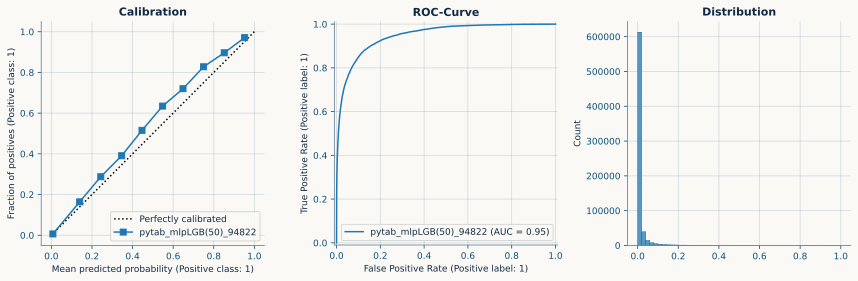

In [36]:
## -- Plot oof distributions --
_, axs = plt.subplots(1, 3, figsize=(12, 4))

CalibrationDisplay.from_predictions(y, oof_preds, n_bins=10, name=n, ax=axs[0])
axs[0].set_title(f"Calibration")

RocCurveDisplay.from_predictions(y, oof_preds, name=n, ax=axs[1])
axs[1].set_title(f"ROC-Curve")

sns.histplot(oof_preds, ax=axs[2], bins=50)
axs[2].set_title(f"Distribution")

plt.tight_layout()
plt.show()

print()

In [14]:
# !rm -r /kaggle/working